# Did Borrowers Pay for Their Risk? Risk-Based Pricing and RAROC for U.S. Mortgages from Loan-Level Fannie Mae and Freddie Mac Data, 2005–2008 and 2018–2021, with Gradient-Boosted PD and LGD and Three Capital Regimes

A lender that prices a loan well charges enough to cover the losses it expects, the capital it must hold against unexpected losses and the cost of running the loan, and charges riskier borrowers more. Before 2008 U.S. mortgage rates barely varied with borrower risk; after the crisis the government-sponsored enterprises introduced explicit risk-based fees. This notebook rebuilds a risk-based price for every loan from its expected loss and capital, and asks how much of that risk borrowers actually paid for, in the crisis vintages of 2005–2008 and in 2018–2021.

**What it does.**

1. It reads loan-level origination and monthly performance data for 50,000 loans per year from Fannie Mae (2005–2008) and Freddie Mac (2018–2021). From them it measures defaults, loss severities and the *spread at origination* (SATO): the note rate minus the market mortgage rate in the week the loan was made.
2. It trains probability-of-default models (logistic regression and LightGBM) and loss-given-default models (linear and LightGBM) on early vintages and tests them on later ones.
3. It computes capital per loan under three regimes: the Basel IRB formula for residential mortgages, the Basel III standardised LTV-based risk weights and the current U.S. 50% risk weight.
4. It builds a risk-based price, made of expected loss, the cost of capital and operating cost, for every loan, and measures how much of it was reflected in what borrowers paid.
5. It compares three pricing schemes on the loans of 2006–2008 against their realised losses: one flat fee, a FICO × LTV grid like the GSEs' loan-level price adjustments, and a loan-level machine-learning price. It reports the risk-adjusted return on capital (RAROC) by risk band.

**Data.** Fannie Mae Single-Family Loan Performance Data and Freddie Mac Single-Family Loan-Level Dataset (samples, downloaded once by hand into `data/` at the repository root); Freddie Mac Primary Mortgage Market Survey 30-year rate and 10-year Treasury yield (FRED).

**Methods.** Loan-level default and loss measurement from performance histories, logistic regression and LightGBM for PD and LGD, out-of-time testing by vintage, Basel IRB and standardised capital, risk-based pricing (expected loss + cost of capital + operating cost), RAROC, SATO regressions and calibration by risk decile.

**Key output.** Default and loss rates by vintage; the out-of-time accuracy of PD and LGD models; capital by FICO and LTV under three regimes; the share of risk priced into mortgage rates before and after the crisis; and the realised RAROC of each pricing scheme.

## 1. Pricing a loan for its risk

**The building blocks of a risk-based price**, as an annual spread on the loan balance:
- *expected loss* (EL) = PD × LGD, spread over the loan's expected life;
- *cost of capital* = capital per dollar × (hurdle rate − risk-free return on the capital), because the lender's shareholders fund the capital and want more than the risk-free rate;
- *operating cost* of originating and servicing the loan.

**RAROC** (risk-adjusted return on capital) = (risk premium charged − expected or realised loss − operating cost) / capital. A loan is priced adequately when its RAROC reaches the hurdle rate.

**Capital.** Three regimes give very different capital for the same loan:
- *Basel IRB:* capital = LGD × [Φ((Φ⁻¹(PD) + √R Φ⁻¹(0.999)) / √(1 − R)) − PD], with R = 15% for residential mortgages and an LGD floor of 10%.
- *Basel III standardised:* risk weights from 20% (LTV ≤ 50%) to 70% (LTV > 100%).
- *U.S. general risk-based rules:* 50% for qualifying first-lien mortgages.

**SATO.** The spread between a loan's note rate and the average market rate when it was made shows how much an individual borrower paid above or below the going rate. If lenders priced risk, SATO should rise with expected loss.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
os.environ.setdefault("KERAS_BACKEND", "torch")

# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import zipfile
import lightgbm as lgb
from scipy.stats import norm
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import r2_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 2006
rng = np.random.default_rng(SEED)
HORIZON = {"Fannie Mae": 60, "Freddie Mac": 36}  # default window, months
VINTAGES = {
    "Fannie Mae": [2005, 2006, 2007, 2008],
    "Freddie Mac": [2018, 2019, 2020, 2021],
}
HURDLE_SPREAD = 0.10  # hurdle return on capital above the risk-free rate
CAPITAL_RATIO = 0.105  # total capital ratio incl. conservation buffer
OPEX = 0.0025  # annual operating cost on the balance
EXPECTED_LIFE = 7.0  # years over which lifetime EL is spread

print(f"lightgbm {lgb.__version__} · run on {dt.date.today():%Y-%m-%d}")

lightgbm 4.7.0 · run on 2026-11-03


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

## 3. Loan-level data

Both datasets use the same layout: an origination file (credit score, loan-to-value, debt-to-income, rate, purpose, occupancy and so on) and a monthly performance file. The Fannie Mae files for 2005–2008 come from its quarterly loan performance data, sampled to 50,000 loans per year in the Freddie Mac sample format. Both are licensed for research and stay in `data/`, never in the repository.

For each loan the notebook records:
- **default:** first 180-day delinquency, short sale, third-party sale, note sale or REO within the default window (60 months for 2005–2008, 36 months for 2018–2021);
- **loss:** the actual loss reported on disposition, over the whole history;
- **severity:** loss divided by the balance at default.

Only 30-year fixed-rate loans are kept.

In [3]:
OC = [
    "fico",
    "first_pay",
    "fthb",
    "maturity",
    "msa",
    "mi_pct",
    "units",
    "occupancy",
    "cltv",
    "dti",
    "upb",
    "ltv",
    "rate",
    "channel",
    "ppm",
    "amort",
    "state",
    "prop_type",
    "zip",
    "loan_id",
    "purpose",
    "term",
    "n_borrowers",
]
PC = ["loan_id", "period", "upb", "dlq", "age", "zb", "loss"]
DEFAULT_ZB = {"02", "03", "09", "15"}


def find_shared(name):
    for d in [PROJECT_DIR, *PROJECT_DIR.parents]:
        if (d / "data" / name).exists():
            return d / "data" / name
    return None


def read_vintage(zp, year, horizon):
    with zipfile.ZipFile(zp) as z:
        o = pd.read_csv(
            z.open(f"sample_orig_{year}.txt"),
            sep="|",
            header=None,
            usecols=range(len(OC)),
            names=OC,
            dtype=str,
        )
        rows = []
        for ch in pd.read_csv(
            z.open(f"sample_perf_{year}.txt"),
            sep="|",
            header=None,
            usecols=[0, 1, 2, 3, 4, 8, 21],
            names=PC,
            dtype=str,
            chunksize=2_000_000,
        ):
            ch["age"] = pd.to_numeric(ch["age"], errors="coerce")
            ch["upb"] = pd.to_numeric(ch["upb"], errors="coerce")
            ch["loss"] = pd.to_numeric(ch["loss"], errors="coerce")
            dlq = pd.to_numeric(
                ch["dlq"].replace({"RA": "99"}), errors="coerce"
            )
            ch["bad"] = (dlq >= 6) | ch["zb"].isin(DEFAULT_ZB)
            rows.append(
                ch[["loan_id", "period", "age", "upb", "bad", "zb", "loss"]]
            )
    p = pd.concat(rows)
    first_bad = p[p["bad"]].groupby("loan_id").agg(default_age=("age", "min"))
    upb_at = p[p["bad"]].sort_values("age").groupby("loan_id")["upb"].first()
    loss = p.groupby("loan_id")["loss"].sum(min_count=1)
    seen = p.groupby("loan_id")["age"].max()
    last_period = p["period"].max()
    o = (
        o.set_index("loan_id")
        .join(first_bad)
        .join(upb_at.rename("default_upb"))
        .join(loss.rename("loss"))
        .join(seen.rename("months_seen"))
    )
    for c in [
        "fico",
        "mi_pct",
        "units",
        "cltv",
        "dti",
        "upb",
        "ltv",
        "rate",
        "term",
        "n_borrowers",
    ]:
        o[c] = pd.to_numeric(o[c], errors="coerce")
    o["default"] = (o["default_age"] <= horizon).astype(int)
    o["vintage"] = year
    o["orig_month"] = pd.to_datetime(
        o["first_pay"], format="%Y%m"
    ) - pd.DateOffset(months=2)
    o["data_end"] = last_period
    return o.reset_index()


def load_all():
    out = []
    for src, folder in [
        ("Fannie Mae", "fannie_mae"),
        ("Freddie Mac", "freddie_mac"),
    ]:
        base = find_shared(folder)
        if base is None:
            continue
        for y in VINTAGES[src]:
            hits = [
                h
                for h in base.rglob(f"sample_{y}.zip")
                if "_to_delete" not in h.parts
            ]
            zp = min(hits, key=lambda h: len(h.parts)) if hits else None
            if zp is not None:
                v = read_vintage(zp, y, HORIZON[src])
                v["source"] = src
                out.append(v)
    return pd.concat(out, ignore_index=True)


LOANS = cached("mortgage_loans_pricing", load_all, max_age_hours=24 * 30)
LOANS["orig_month"] = pd.to_datetime(LOANS["orig_month"])
LOANS = LOANS[
    (LOANS["amort"] == "FRM")
    & (LOANS["term"].between(300, 360))
    & LOANS["fico"].between(300, 850)
    & LOANS["ltv"].between(1, 200)
    & LOANS["rate"].between(1, 15)
].copy()
LOANS["dti"] = LOANS["dti"].where(LOANS["dti"].between(1, 65))
LOANS["cltv"] = LOANS["cltv"].where(
    LOANS["cltv"].between(1, 200), LOANS["ltv"]
)


def fetch_rates():
    return pd.DataFrame({
        "pmms30": fred.get_series("MORTGAGE30US"),
        "ust10": fred.get_series("DGS10"),
    })


RATES = cached("pmms_ust10", fetch_rates, max_age_hours=24 * 7)
RATES.index = pd.to_datetime(RATES.index)
monthly = RATES.resample("MS").mean()
LOANS = LOANS.join(monthly, on="orig_month")
LOANS["sato"] = LOANS["rate"] - LOANS["pmms30"]
LOANS["severity"] = (
    (-LOANS["loss"] / LOANS["default_upb"])
    .where(
        LOANS["default"].eq(1)
        & LOANS["loss"].notna()
        # 2018–2021: too few liquidations
        & LOANS["source"].eq("Fannie Mae")
    )
    .clip(-0.2, 1.5)
)
VINT = LOANS.groupby(["source", "vintage"]).agg(
    loans=("loan_id", "size"),
    fico=("fico", "mean"),
    ltv=("ltv", "mean"),
    dti=("dti", "mean"),
    default_rate=("default", "mean"),
    severity=("severity", "mean"),
    sato_sd=("sato", "std"),
    pmms30=("pmms30", "mean"),
)
VINT["loss rate (default × severity)"] = (
    VINT["default_rate"] * VINT["severity"]
)
VINT.style.format({
    "loans": "{:,.0f}",
    "fico": "{:.0f}",
    "ltv": "{:.1f}",
    "dti": "{:.1f}",
    "default_rate": "{:.2%}",
    "severity": "{:.1%}",
    "sato_sd": "{:.2f}",
    "pmms30": "{:.2f}",
    "loss rate (default × severity)": "{:.2%}",
})

## 4. PD and LGD models, tested out of time

**PD.** Each source has its own default window, so each gets its own models:
- **Fannie Mae:** trained on 2005 loans and tested on 2006–2008;
- **Freddie Mac:** trained on 2018 and tested on 2019–2021.

The features are those a lender sees at origination: credit score, LTV and combined LTV, DTI, mortgage insurance, purpose, occupancy, property type, units, channel, number of borrowers, first-time buyer and loan size. Regional effects are captured by the state's default rate in the training vintage, a target encoding fitted only on training data.

**LGD.** Fitted only on defaulted Fannie Mae loans with a reported loss (2005 train, 2006–2008 test), from the same features. In 2018–2021 there are too few completed liquidations to estimate severity, so the 2005–2008 model is applied with a downturn floor of 10%.

In [4]:
CAT = ["purpose", "occupancy", "prop_type", "channel", "fthb"]
NUM = [
    "fico",
    "ltv",
    "cltv",
    "dti",
    "mi_pct",
    "units",
    "n_borrowers",
    "log_upb",
]


def design(d, enc=None):
    X = d[NUM[:-1]].copy()
    X["log_upb"] = np.log(d["upb"].clip(10_000))
    for c in CAT:
        X = X.join(pd.get_dummies(d[c].fillna("U"), prefix=c, dtype=float))
    X["state_rate"] = (
        d["state"].map(enc).fillna(np.nanmean(list(enc.values())))
    )
    return X


def fit_pd(src, train_v):
    d = LOANS[LOANS["source"] == src]
    tr, te = d[d["vintage"].isin(train_v)], d[~d["vintage"].isin(train_v)]
    enc = tr.groupby("state")["default"].mean().to_dict()
    Xtr, Xte = design(tr, enc), design(te, enc).reindex(
        columns=design(tr, enc).columns, fill_value=0
    )
    logit = make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=2000, C=0.5)
    ).fit(Xtr.fillna(Xtr.median()), tr["default"])
    gbm = lgb.LGBMClassifier(
        n_estimators=500,
        learning_rate=0.03,
        num_leaves=31,
        min_child_samples=100,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.8,
        random_state=SEED,
        verbose=-1,
    ).fit(Xtr, tr["default"])
    p_l = logit.predict_proba(Xte.fillna(Xtr.median()))[:, 1]
    p_g = gbm.predict_proba(Xte)[:, 1]
    rows = []
    for v in sorted(te["vintage"].unique()):
        m = (te["vintage"] == v).to_numpy()
        y = te["default"].to_numpy()[m]
        rows.append({
            "source": src,
            "test vintage": v,
            "default rate": y.mean(),
            "AUC FICO only": roc_auc_score(y, -te["fico"].to_numpy()[m]),
            "AUC logit": roc_auc_score(y, p_l[m]),
            "AUC LightGBM": roc_auc_score(y, p_g[m]),
            "mean PD LightGBM": p_g[m].mean(),
        })
    full = design(d, enc).reindex(columns=Xtr.columns, fill_value=0)
    return (
        gbm,
        pd.Series(gbm.predict_proba(full)[:, 1], index=d.index),
        pd.DataFrame(rows),
    )


gbm_fn, PD_FN, ev_fn = fit_pd("Fannie Mae", [2005])
gbm_fm, PD_FM, ev_fm = fit_pd("Freddie Mac", [2018])
LOANS["pd_model"] = pd.concat([PD_FN, PD_FM])
PD_EVAL = pd.concat([ev_fn, ev_fm], ignore_index=True)

dd = LOANS[(LOANS["source"] == "Fannie Mae") & LOANS["severity"].notna()]
enc_s = dd[dd["vintage"] == 2005].groupby("state")["severity"].mean().to_dict()
Xs = design(dd, enc_s)
trs = (dd["vintage"] == 2005).to_numpy()
lin_lgd = LinearRegression().fit(
    Xs[trs].fillna(Xs[trs].median()), dd["severity"][trs]
)
gbm_lgd = lgb.LGBMRegressor(
    n_estimators=400,
    learning_rate=0.03,
    num_leaves=15,
    min_child_samples=50,
    random_state=SEED,
    verbose=-1,
).fit(Xs[trs], dd["severity"][trs])
LGD_EVAL = pd.Series({
    "defaults with a loss, train (2005)": trs.sum(),
    "test (2006–2008)": (~trs).sum(),
    "mean severity train": dd["severity"][trs].mean(),
    "mean severity test": dd["severity"][~trs].mean(),
    "R² linear (test)": r2_score(
        dd["severity"][~trs],
        lin_lgd.predict(Xs[~trs].fillna(Xs[trs].median())),
    ),
    "R² LightGBM (test)": r2_score(
        dd["severity"][~trs], gbm_lgd.predict(Xs[~trs])
    ),
})
Xall = design(LOANS, enc_s).reindex(columns=Xs.columns, fill_value=0)
LOANS["lgd_model"] = np.clip(gbm_lgd.predict(Xall), 0.10, 1.0)
display(
    PD_EVAL.style.format({
        "default rate": "{:.2%}",
        "mean PD LightGBM": "{:.2%}",
        "AUC FICO only": "{:.3f}",
        "AUC logit": "{:.3f}",
        "AUC LightGBM": "{:.3f}",
    })
)
LGD_EVAL.to_frame("value").style.format("{:,.3f}")

,source,test vintage,default rate,AUC FICO only,AUC logit,AUC LightGBM,mean PD LightGBM
0,Fannie Mae,2006,9.11%,0.697,0.776,0.768,4.88%
1,Fannie Mae,2007,12.33%,0.708,0.791,0.773,5.15%
2,Fannie Mae,2008,8.56%,0.722,0.802,0.772,4.22%
3,Freddie Mac,2019,3.36%,0.686,0.740,0.718,2.74%
4,Freddie Mac,2020,1.25%,0.691,0.758,0.739,2.20%
5,Freddie Mac,2021,0.78%,0.728,0.783,0.740,2.61%


,value
"defaults with a loss, train (2005)","1,305.000"
test (2006–2008),"7,966.000"
mean severity train,0.534
mean severity test,0.534
R² linear (test),0.055
R² LightGBM (test),0.035


## 5. Capital under three regimes, and the risk-based price

The model PD covers the default window. It is converted to a one-year PD, (1 − (1 − PD)^(12/window)), for the IRB formula, and spread over an expected life of seven years for the annual expected loss. Capital is the total capital ratio (10.5%, including the conservation buffer) times risk-weighted assets.

**Risk-based price** (annual, on the balance) = EL / life + capital × 10% hurdle spread + 0.25% operating cost. The IRB capital is used here, because it is the only regime in which capital follows the loan's own risk.

In [5]:
def irb_k(pd1, lgd, R=0.15):
    pd1 = np.clip(pd1, 0.0003, 0.999)
    return (
        lgd
        * norm.cdf(
            (norm.ppf(pd1) + np.sqrt(R) * norm.ppf(0.999)) / np.sqrt(1 - R)
        )
        - pd1 * lgd
    )


def sa_rw(ltv):
    return np.select(
        [ltv <= 50, ltv <= 60, ltv <= 80, ltv <= 90, ltv <= 100],
        [0.20, 0.25, 0.30, 0.40, 0.50],
        0.70,
    )


win = LOANS["source"].map(HORIZON)
LOANS["pd_1y"] = 1 - (1 - LOANS["pd_model"]) ** (12 / win)
lgd_reg = np.maximum(LOANS["lgd_model"], 0.10)
LOANS["cap_irb"] = 12.5 * irb_k(LOANS["pd_1y"], lgd_reg) * CAPITAL_RATIO
LOANS["cap_sa"] = sa_rw(LOANS["ltv"]) * CAPITAL_RATIO
LOANS["cap_us"] = 0.50 * CAPITAL_RATIO
life_pd = 1 - (1 - LOANS["pd_1y"]) ** EXPECTED_LIFE
LOANS["el_annual"] = life_pd * LOANS["lgd_model"] / EXPECTED_LIFE
LOANS["risk_price"] = (
    LOANS["el_annual"] + LOANS["cap_irb"] * HURDLE_SPREAD + OPEX
)

LOANS["fico band"] = pd.cut(
    LOANS["fico"],
    [300, 660, 700, 740, 780, 851],
    labels=["<660", "660–699", "700–739", "740–779", "780+"],
    right=False,
)
LOANS["ltv band"] = pd.cut(
    LOANS["ltv"],
    [0, 60, 80, 90, 95, 200],
    labels=["≤60", "60–80", "80–90", "90–95", ">95"],
)
CAP = (
    LOANS[LOANS["source"] == "Fannie Mae"]
    .groupby(["fico band", "ltv band"], observed=True)[
        ["cap_irb", "cap_sa", "cap_us"]
    ]
    .mean()
    .mul(100)
    .unstack("ltv band")
)
PRICE_GRID = (
    LOANS.groupby(["source", "fico band"], observed=True)["risk_price"]
    .mean()
    .unstack("fico band")
    .mul(100)
)
display(
    CAP["cap_irb"]
    .style.format("{:.2f}")
    .set_caption("IRB capital per $100, Fannie Mae 2005–2008")
)
display(
    CAP["cap_sa"]
    .style.format("{:.2f}")
    .set_caption("Basel III standardised capital per $100")
)
PRICE_GRID.style.format("{:.2f}").set_caption("Risk-based price, % a year")

ltv band,≤60,60–80,80–90,90–95,>95
fico band,,,,,
<660,7.81,12.17,10.09,6.16,8.21
660–699,3.47,8.52,8.10,5.18,5.51
700–739,2.16,6.42,6.54,4.42,4.34
740–779,1.07,4.03,4.10,2.48,2.59
780+,0.51,1.74,2.18,1.22,1.08


ltv band,≤60,60–80,80–90,90–95,>95
fico band,,,,,
<660,2.36,3.15,4.20,5.25,5.25
660–699,2.35,3.15,4.20,5.25,5.25
700–739,2.34,3.15,4.20,5.25,5.25
740–779,2.33,3.15,4.20,5.25,5.25
780+,2.30,3.15,4.20,5.25,5.25


fico band,<660,660–699,700–739,740–779,780+
source,,,,,
Fannie Mae,2.41,1.69,1.28,0.84,0.47
Freddie Mac,2.21,1.58,1.17,0.79,0.56


## 6. Did borrowers pay for their risk?

Within each origination month, SATO is regressed on the model's risk-based price (both in percentage points). A slope of 1 would mean that every point of extra risk cost the borrower a point in rate; a slope of zero, that risk was not priced at all. The regression controls for the origination month, so it compares borrowers who borrowed at the same time.

In [6]:
def pricing_slope(d):
    x = d["risk_price"] * 100
    y = d["sato"]
    xm = x - x.groupby(d["orig_month"]).transform("mean")
    ym = y - y.groupby(d["orig_month"]).transform("mean")
    ok = xm.notna() & ym.notna()
    b = (xm[ok] * ym[ok]).sum() / (xm[ok] ** 2).sum()
    resid = ym[ok] - b * xm[ok]
    se = np.sqrt((resid**2).sum() / (ok.sum() - 2) / (xm[ok] ** 2).sum())
    return pd.Series({
        "slope (pts of rate per pt of risk price)": b,
        "s.e.": se,
        "risk price, 90th − 10th pct (pts)": x.quantile(0.9) - x.quantile(0.1),
        "SATO, 90th − 10th pct (pts)": y.quantile(0.9) - y.quantile(0.1),
    })


SLOPES = LOANS.groupby(["source", "vintage"]).apply(pricing_slope)
SATO_BY_FICO = (
    LOANS.groupby(["source", "fico band"], observed=True)["sato"]
    .mean()
    .unstack("fico band")
)
display(SLOPES.style.format("{:.3f}"))
SATO_BY_FICO.style.format("{:+.2f}").set_caption(
    "Average SATO by credit score (pts)"
)

fico band,<660,660–699,700–739,740–779,780+
source,,,,,
Fannie Mae,+0.20,+0.09,+0.05,+0.00,-0.03
Freddie Mac,+0.68,+0.48,+0.30,+0.19,+0.15


## 7. Three pricing schemes against realised losses, 2006–2008

On the Fannie Mae loans of 2006–2008, which the PD model never saw, three ways of charging for credit risk are compared with what the loans actually lost:

- **flat fee:** every loan pays the average risk-based price of the 2005 vintage;
- **FICO × LTV grid:** the average realised annual loss and capital cost of each FICO band × LTV band cell in 2005, plus operating cost, the logic of the GSEs' loan-level price adjustments;
- **loan-level ML price:** the risk-based price from the LightGBM PD and LGD.

For each scheme and each decile of its price, the realised annual loss rate is the lifetime loss over the balance divided by the expected life. The realised RAROC by FICO band is (fee charged − realised annual loss − operating cost) / IRB capital.

In [7]:
fn = LOANS[LOANS["source"] == "Fannie Mae"].copy()
fn["real_loss"] = (-fn["loss"].fillna(0) / fn["upb"]).clip(
    0, 1.5
) / EXPECTED_LIFE
base = fn[fn["vintage"] == 2005]
test = fn[fn["vintage"] > 2005].copy()
cell = base.groupby(["fico band", "ltv band"], observed=True).apply(
    lambda d: d["real_loss"].mean()
    + d["cap_irb"].mean() * HURDLE_SPREAD
    + OPEX
)
test["fee flat"] = base["risk_price"].mean()
test["fee grid"] = (
    test.set_index(["fico band", "ltv band"]).index.map(cell).to_numpy()
)
test["fee grid"] = test["fee grid"].fillna(test["fee flat"])
test["fee ML"] = test["risk_price"]
SCHEMES = {
    "flat fee": "fee flat",
    "FICO × LTV grid": "fee grid",
    "loan-level ML price": "fee ML",
}
rows = []
for name, col in SCHEMES.items():
    cost = test["real_loss"] + OPEX + test["cap_irb"] * HURDLE_SPREAD
    rows.append({
        "scheme": name,
        "mean fee (% a year)": test[col].mean() * 100,
        "mean realised loss (% a year)": test["real_loss"].mean() * 100,
        "rank corr. fee vs realised loss": (
            test[col].corr(test["real_loss"], method="spearman")
            if test[col].nunique() > 1
            else 0.0
        ),
        "cross-subsidy (mean |fee − cost|, pts)": (
            (test[col] - cost).abs().mean() * 100
        ),
        "loans whose fee fell short of their cost": (test[col] < cost).mean(),
    })
SCHEME_EVAL = pd.DataFrame(rows).set_index("scheme")
test["ml decile"] = (
    pd.qcut(test["fee ML"].rank(method="first"), 10, labels=False) + 1
)
CALIB = (
    test.groupby("ml decile")
    .agg(
        fee=("fee ML", "mean"),
        realised_loss=("real_loss", "mean"),
        default_rate=("default", "mean"),
    )
    .mul([100, 100, 1])
)
RAROC = test.groupby("fico band", observed=True).apply(
    lambda d: pd.Series({
        f"RAROC, {k}": (
            (d[c] - d["real_loss"] - OPEX).sum() / d["cap_irb"].sum()
        )
        for k, c in SCHEMES.items()
    })
)
display(
    SCHEME_EVAL.style.format({
        "mean fee (% a year)": "{:.2f}",
        "mean realised loss (% a year)": "{:.2f}",
        "rank corr. fee vs realised loss": "{:.2f}",
        "cross-subsidy (mean |fee − cost|, pts)": "{:.2f}",
        "loans whose fee fell short of their cost": "{:.1%}",
    })
)
display(
    CALIB.style.format(
        {"fee": "{:.2f}", "realised_loss": "{:.2f}", "default_rate": "{:.1%}"}
    )
)
RAROC.style.format("{:+.1%}")

,mean fee (% a year),mean realised loss (% a year),rank corr. fee vs realised loss,"cross-subsidy (mean |fee − cost|, pts)",loans whose fee fell short of their cost
scheme,,,,,
flat fee,1.28,0.52,0.00,1.20,19.7%
FICO × LTV grid,1.17,0.52,0.18,1.01,20.7%
loan-level ML price,1.22,0.52,0.23,0.83,7.1%


,fee,realised_loss,default_rate
ml decile,,,
1,0.28,0.03,1.0%
2,0.31,0.07,2.1%
3,0.37,0.12,3.4%
4,0.46,0.17,4.9%
5,0.60,0.25,6.4%
6,0.79,0.36,8.5%
7,1.08,0.47,10.6%
8,1.53,0.78,15.1%
9,2.29,1.08,20.2%


,"RAROC, flat fee","RAROC, FICO × LTV grid","RAROC, loan-level ML price"
fico band,,,
<660,-0.6%,+7.4%,+9.9%
660–699,+3.4%,+8.2%,+8.7%
700–739,+8.6%,+7.5%,+8.4%
740–779,+21.4%,+8.6%,+8.6%
780+,+60.9%,+7.5%,+5.4%


## 8. Charts and dashboard

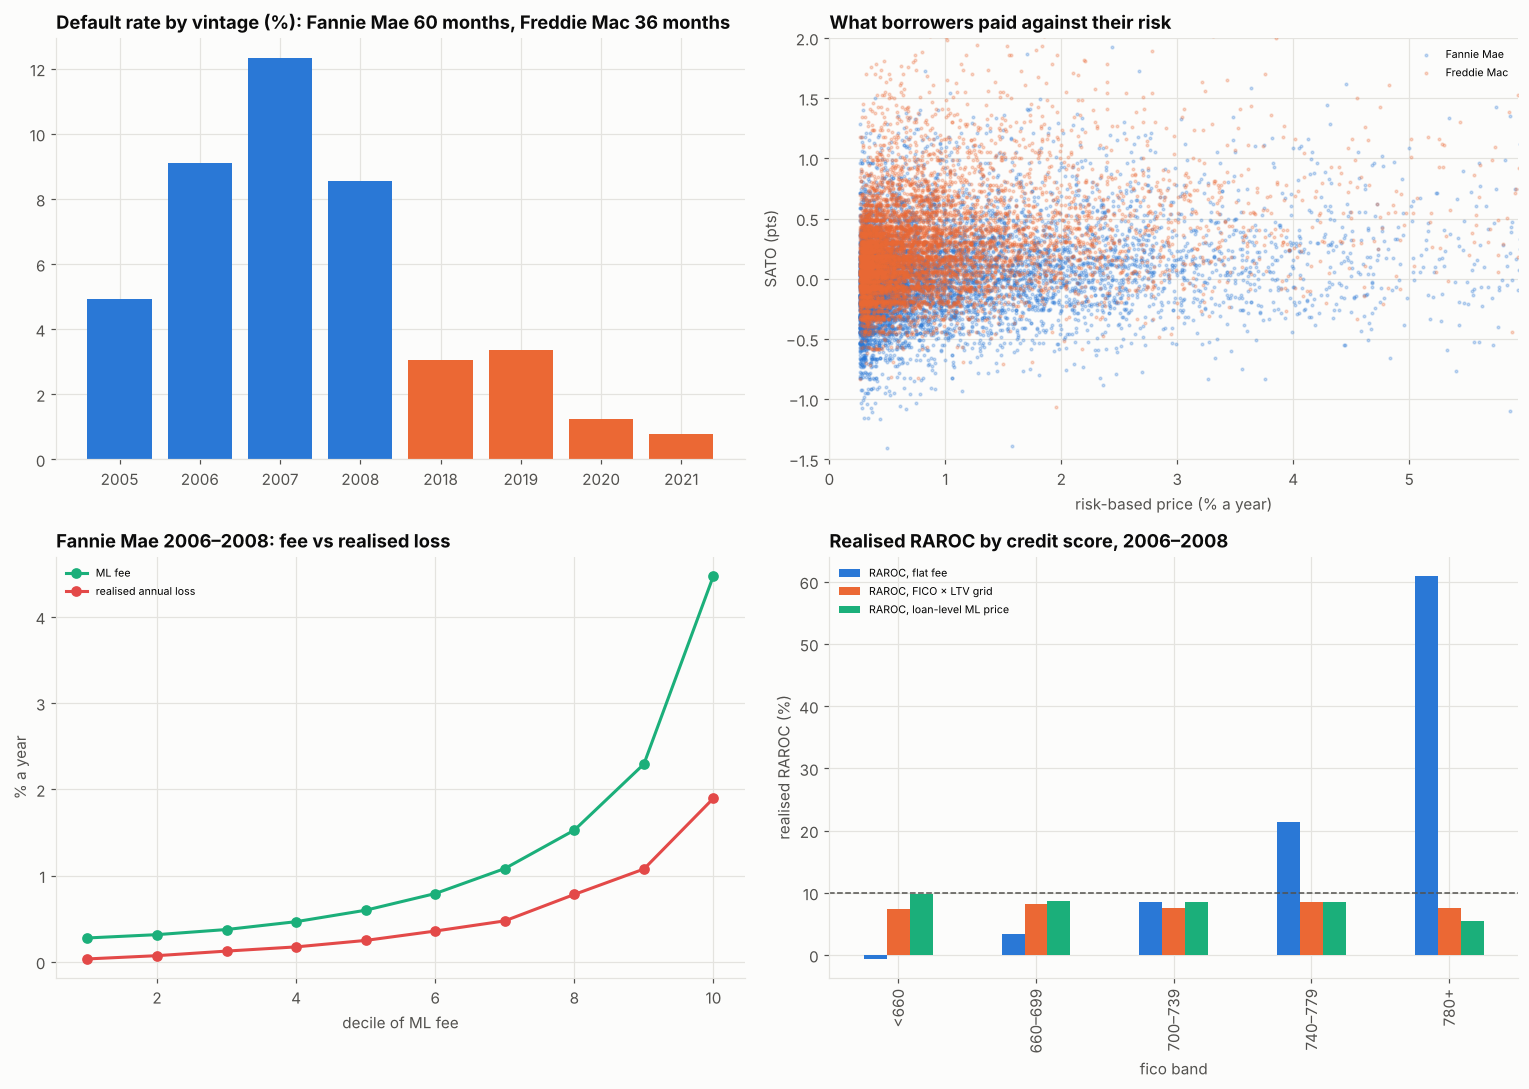

In [8]:
fig, ax = plt.subplots(2, 2, figsize=(14, 10))
a = ax[0, 0]
v = VINT.reset_index()
a.bar(
    v["vintage"].astype(str),
    v["default_rate"] * 100,
    color=[PALETTE[0]] * 4 + [PALETTE[1]] * 4,
)
a.set_title(
    "Default rate by vintage (%): Fannie Mae 60 months, Freddie Mac 36 months"
)
a = ax[0, 1]
for (src, g), col in zip(LOANS.groupby("source"), PALETTE):
    s = g.sample(min(8000, len(g)), random_state=SEED)
    a.scatter(
        s["risk_price"] * 100, s["sato"], s=3, alpha=0.25, color=col, label=src
    )
a.set_xlim(0, np.percentile(LOANS["risk_price"] * 100, 99))
a.set_ylim(-1.5, 2)
a.set_xlabel("risk-based price (% a year)")
a.set_ylabel("SATO (pts)")
a.set_title("What borrowers paid against their risk")
a.legend(fontsize=7)
a = ax[1, 0]
a.plot(CALIB.index, CALIB["fee"], marker="o", color=PALETTE[2], label="ML fee")
a.plot(
    CALIB.index,
    CALIB["realised_loss"],
    marker="o",
    color=STATUS["red"],
    label="realised annual loss",
)
a.set_xlabel("decile of ML fee")
a.set_ylabel("% a year")
a.set_title("Fannie Mae 2006–2008: fee vs realised loss")
a.legend(fontsize=7)
a = ax[1, 1]
RAROC.mul(100).plot.bar(ax=a, color=PALETTE[:3])
a.axhline(HURDLE_SPREAD * 100, color=INK_2, ls="--", lw=1)
a.set_ylabel("realised RAROC (%)")
a.set_title("Realised RAROC by credit score, 2006–2008")
a.legend(fontsize=7)
fig.tight_layout()
save_fig(fig, "01_mortgage_pricing")
plt.show()

In [9]:
dash = make_subplots(
    rows=2,
    cols=2,
    subplot_titles=(
        "Out-of-time AUC by vintage",
        "IRB capital per $100 by FICO and LTV (Fannie Mae)",
        "SATO by credit score (pts)",
        "Capital per $100 by regime and LTV band",
    ),
)
for c, col in zip(["AUC FICO only", "AUC logit", "AUC LightGBM"], PALETTE):
    dash.add_trace(
        go.Bar(
            x=PD_EVAL["test vintage"].astype(str),
            y=PD_EVAL[c],
            name=c,
            marker_color=col,
        ),
        1,
        1,
    )
dash.add_trace(
    go.Heatmap(
        z=CAP["cap_irb"].to_numpy(),
        x=[str(c) for c in CAP["cap_irb"].columns],
        y=[str(i) for i in CAP["cap_irb"].index],
        colorscale="Blues",
        showscale=False,
    ),
    1,
    2,
)
for src, col in zip(SATO_BY_FICO.index, PALETTE[2:]):
    dash.add_trace(
        go.Bar(
            x=[str(c) for c in SATO_BY_FICO.columns],
            y=SATO_BY_FICO.loc[src],
            name=src,
            marker_color=col,
        ),
        2,
        1,
    )
cap_ltv = (
    LOANS.groupby("ltv band", observed=True)[
        ["cap_irb", "cap_sa", "cap_us"]
    ].mean()
    * 100
)
for c, nm, col in zip(
    cap_ltv.columns, ["IRB", "Basel III SA", "U.S. 50%"], PALETTE[4:]
):
    dash.add_trace(
        go.Bar(
            x=[str(i) for i in cap_ltv.index],
            y=cap_ltv[c],
            name=nm,
            marker_color=col,
        ),
        2,
        2,
    )
dash.update_layout(
    height=950,
    width=1400,
    template="simple_white",
    barmode="group",
    title="Risk-based mortgage pricing and RAROC",
)
save_dashboard(dash, "dashboard")
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 9. Reading the results and limitations

**The crisis vintages lost far more than the recent ones.** Of the 30-year fixed-rate loans in the samples, the share that defaulted within five years was:

| Fannie Mae vintage | Default rate (5 years) | Severity | Lifetime loss |
|---|---|---|---|
| 2005 | 4.9% | 53% | 2.6% |
| 2006 | 9.1% | 58% | 5.3% |
| 2007 | 12.3% | 55% | 6.7% |
| 2008 | 8.6% | 46% | 3.9% |

The 2018–2021 Freddie Mac loans, with average credit scores about 25 points higher, defaulted at 0.8–3.4% within three years. The higher figures for 2018 and 2019 are mostly borrowers who stopped paying under the 2020 forbearance programmes; many of them later resumed payments. Too few of those loans have been liquidated to measure their severity.

**Default can be ranked out of time; severity cannot.** Trained on one vintage and tested on the next three:

| Test vintages | AUC, credit score only | AUC, logistic regression | AUC, LightGBM |
|---|---|---|---|
| Fannie Mae 2006–2008 | 0.70–0.72 | 0.78–0.80 | 0.77 |
| Freddie Mac 2019–2021 | 0.69–0.73 | 0.74–0.78 | 0.72–0.74 |

The logistic regression is slightly better than gradient boosting out of time: the relationships that matter (credit score, LTV, DTI, mortgage insurance, purpose) are close to monotone, and the trees fit the 2005 vintage too closely. Neither model anticipated the level of defaults in 2006–2007; LightGBM predicted about 5% against realised 9–12%, because the 2005 vintage it learned from had not yet seen house prices fall. Loss severity, at about 53–58% in every crisis vintage, is almost unpredictable from origination data (out-of-time R² 0.06 linear, 0.04 LightGBM). It depends on house prices and foreclosure timelines after default, not on the borrower.

**Capital depends on the regime more than on the loan.** For the 2005–2008 loans, IRB capital per \$100 ranges from \$0.51 (credit score 780+, LTV ≤ 60%) to \$12.17 (below 660, LTV 60–80%). The Basel III standardised approach gives \$2.30–5.25, driven by LTV alone, and the U.S. rule a flat \$5.25. High-LTV loans carry less IRB capital than 60–80% LTV loans with the same score. Loans above 80% LTV need mortgage insurance and were underwritten more strictly, so the model gives them lower default rates, and the IRB formula follows. The standardised weights, which rise with LTV whatever the insurance, do not.

**Borrowers paid a small fraction of their risk.** Within each origination month, a one-point increase in the risk-based price raised the borrower's rate by:
- **Fannie Mae 2005–2007:** 0.05–0.06 points (2008: 0.10);
- **Freddie Mac 2018–2021:** 0.10–0.15 points.

All slopes are precisely estimated (standard errors 0.001–0.002). The risk-based price varied by about 2.7 points between the 10th and 90th percentile borrower; the rate they paid above the market varied by less than one point.

After the crisis the gap by credit score widened, because the GSEs' loan-level price adjustments added explicit fees for lower scores and higher LTVs:
- **Fannie Mae 2005–2008:** borrowers below 660 paid 0.20 points more than the market average, and those above 780 paid 0.03 less.
- **Freddie Mac 2018–2021:** the corresponding figures were 0.68 and 0.15.

Most of the credit risk was, and still is, absorbed by the guarantee fee, mortgage insurance and the GSEs' capital rather than by the borrower's rate.

**Charging for risk loan by loan removes most of the cross-subsidy.** On the Fannie Mae loans of 2006–2008, none of which the models saw:

| Pricing scheme | Rank correlation with realised loss | Mean gap between fee and cost (pts) | Loans whose fee fell short of their cost |
|---|---|---|---|
| Flat fee | 0.00 | 1.20 | 20% |
| FICO × LTV grid | 0.18 | 1.01 | 21% |
| Loan-level ML price | 0.23 | 0.83 | 7% |

The ML fee rises in line with realised losses across its deciles: from 0.28% a year in the lowest decile, where loans lost 0.03% a year, to 4.48% in the highest, where they lost 1.90%. Realised RAROC by credit score shows who paid for whom:
- **Flat fee:** −1% on borrowers below 660 and 61% on borrowers above 780. The best borrowers subsidised the worst.
- **Grid and ML price:** they bring every band to 5–10%, close to the 10% hurdle spread.

Because the fee includes the cost of capital at the hurdle, a realised RAROC below 10% means that losses were higher than the fee assumed. They were, in 2006–2008, even for the ML price.

**What this means for pricing.** A risk-based price built from an ordinary PD model, a fixed severity and IRB capital would have charged the riskiest crisis-era borrowers several points a year more and the safest less. Before the crisis the market charged them almost the same. Machine learning adds little to the ranking of defaults over a well-specified logistic regression. Its value here is in making the price follow the loan's own risk instead of a coarse grid.

**Limitations.**
- **Samples:** the Fannie Mae 2005–2008 sample was drawn in the Freddie Mac format from the quarterly files; both samples cover only 30-year fixed-rate conforming loans, not subprime or jumbo loans.
- **Default and loss:** default is the first 180-day delinquency or disposition within the window. Losses come from disposition records, so loans still in foreclosure or modified carry no loss. 2018–2021 defaults are inflated by forbearance.
- **SATO:** measured against the monthly average Primary Mortgage Market Survey rate, which assumes average points and fees. Points paid and lender credits are not in the data.
- **Pricing assumptions:** the risk-based price uses a 7-year expected life, a 10% hurdle spread on capital, a 10.5% capital ratio and 0.25% operating cost. The ex-post comparison spreads lifetime losses over the same seven years.
- **Not modelled:** mortgage insurance recoveries beyond what the loss records include, prepayment risk and interest-rate risk.

In [10]:
VINT.to_csv(OUT_DIR / "vintages.csv")
PD_EVAL.to_csv(OUT_DIR / "pd_out_of_time.csv")
LGD_EVAL.to_csv(OUT_DIR / "lgd_out_of_time.csv")
CAP.to_csv(OUT_DIR / "capital_by_fico_ltv.csv")
PRICE_GRID.to_csv(OUT_DIR / "risk_price_by_fico.csv")
SLOPES.to_csv(OUT_DIR / "sato_pricing_slopes.csv")
SATO_BY_FICO.to_csv(OUT_DIR / "sato_by_fico.csv")
SCHEME_EVAL.to_csv(OUT_DIR / "pricing_schemes.csv")
CALIB.to_csv(OUT_DIR / "ml_fee_calibration.csv")
RAROC.to_csv(OUT_DIR / "raroc_by_fico.csv")
print("Outputs written:", ", ".join(sorted(p.name for p in OUT_DIR.iterdir())))

Outputs written: 01_mortgage_pricing.png, capital_by_fico_ltv.csv, dashboard.html, dashboard.png, lgd_out_of_time.csv, ml_fee_calibration.csv, pd_out_of_time.csv, pricing_schemes.csv, raroc_by_fico.csv, risk_price_by_fico.csv, sato_by_fico.csv, sato_pricing_slopes.csv, vintages.csv


## References

### Finance and regulation

- Basel Committee on Banking Supervision. (2017). *Basel III: Finalising post-crisis reforms*. Bank for International Settlements. https://www.bis.org/bcbs/publ/d424.htm
- Gordy, M. B. (2003). A risk-factor model foundation for ratings-based bank capital rules. *Journal of Financial Intermediation, 12*(3), 199–232. https://doi.org/10.1016/S1042-9573(03)00040-8
- Zaik, E., Walter, J., Retting, G., & James, C. (1996). RAROC at Bank of America: From theory to practice. *Journal of Applied Corporate Finance, 9*(2), 83–93. https://doi.org/10.1111/j.1745-6622.1996.tb00117.x
- Demyanyk, Y., & Van Hemert, O. (2011). Understanding the subprime mortgage crisis. *Review of Financial Studies, 24*(6), 1848–1880. https://doi.org/10.1093/rfs/hhp033
- Mayer, C., Pence, K., & Sherlund, S. M. (2009). The rise in mortgage defaults. *Journal of Economic Perspectives, 23*(1), 27–50. https://doi.org/10.1257/jep.23.1.27
- Freddie Mac. (2026). *Single-Family Loan-Level Dataset* [Data set]. https://www.freddiemac.com/research/datasets/sf-loanlevel-dataset
- Fannie Mae. (2026). *Single-Family Loan Performance Data* [Data set]. https://capitalmarkets.fanniemae.com/credit-risk-transfer/single-family-credit-risk-transfer/fannie-mae-single-family-loan-performance-data

### Machine learning and deep learning

- Fuster, A., Goldsmith-Pinkham, P., Ramadorai, T., & Walther, A. (2022). Predictably unequal? The effects of machine learning on credit markets. *The Journal of Finance, 77*(1), 5–47. https://doi.org/10.1111/jofi.13090
- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems, 30*. https://proceedings.neurips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html